# Análise Exploratória — Carga Elétrica Brasileira

Parte do projeto **O Impacto dos Data Centers na Demanda Elétrica Brasileira até 2036: Uma Análise com Dados do ONS, ANEEL e EPE**. A série diária do ONS para 2024–2026 combina dados operacionais e componentes estimados, incluindo MMGD estimada e previsão de geração de pequenas usinas. A carga do SIN não equivale ao consumo total da EPE. Novembro de 2026 é parcial.


## 1. Carregamento dos Dados
Leitura e consolidação dos arquivos CSV.

In [1]:

import pandas as pd
from pathlib import Path

# Encontrar a raiz do projeto
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

PASTA_DADOS = BASE_DIR / "data" / "raw"

arquivos = sorted(
    PASTA_DADOS.glob("CARGA_ENERGIA_*.csv")
)

print(f"Arquivos encontrados: {len(arquivos)}")

bases = []

for arquivo in arquivos:
    df_temp = pd.read_csv(
        arquivo,
        sep=";",
        encoding="utf-8-sig"
    )

    df_temp["arquivo_origem"] = arquivo.name
    bases.append(df_temp)

df = pd.concat(bases, ignore_index=True)

print(f"Total de registros: {len(df):,}")
display(df.head())


Arquivos encontrados: 3
Total de registros: 4,164


,id_subsistema,nom_subsistema,din_instante,val_cargaenergiamwmed,arquivo_origem
0,N,Norte,2024-01-01,6532.986042,CARGA_ENERGIA_2024.csv
1,NE,Nordeste,2024-01-01,11658.740083,CARGA_ENERGIA_2024.csv
2,S,Sul,2024-01-01,10472.403292,CARGA_ENERGIA_2024.csv
3,SE,Sudeste/Centro-Oeste,2024-01-01,35089.386708,CARGA_ENERGIA_2024.csv
4,N,Norte,2024-01-02,7154.334333,CARGA_ENERGIA_2024.csv


## 2. Qualidade dos Dados
Verificação de estrutura, nulos e duplicados.

In [2]:

print("DIMENSÕES")
print(df.shape)

print("\nCOLUNAS")
print(df.columns.tolist())

print("\nTIPOS DE DADOS")
df.info()

print("\nVALORES AUSENTES")
display(df.isna().sum())

print("\nREGISTROS DUPLICADOS")
print(df.duplicated().sum())

print("\nAMOSTRA DOS DADOS")
display(df.head(10))


DIMENSÕES
(4164, 5)

COLUNAS
['id_subsistema', 'nom_subsistema', 'din_instante', 'val_cargaenergiamwmed', 'arquivo_origem']

TIPOS DE DADOS
<class 'pandas.DataFrame'>
RangeIndex: 4164 entries, 0 to 4163
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_subsistema          4164 non-null   str    
 1   nom_subsistema         4164 non-null   str    
 2   din_instante           4164 non-null   str    
 3   val_cargaenergiamwmed  4164 non-null   float64
 4   arquivo_origem         4164 non-null   str    
dtypes: float64(1), str(4)
memory usage: 336.1 KB

VALORES AUSENTES


id_subsistema            0
nom_subsistema           0
din_instante             0
val_cargaenergiamwmed    0
arquivo_origem           0
dtype: int64


REGISTROS DUPLICADOS
0

AMOSTRA DOS DADOS


,id_subsistema,nom_subsistema,din_instante,val_cargaenergiamwmed,arquivo_origem
0,N,Norte,2024-01-01,6532.986042,CARGA_ENERGIA_2024.csv
1,NE,Nordeste,2024-01-01,11658.740083,CARGA_ENERGIA_2024.csv
2,S,Sul,2024-01-01,10472.403292,CARGA_ENERGIA_2024.csv
3,SE,Sudeste/Centro-Oeste,2024-01-01,35089.386708,CARGA_ENERGIA_2024.csv
4,N,Norte,2024-01-02,7154.334333,CARGA_ENERGIA_2024.csv
5,NE,Nordeste,2024-01-02,12642.992083,CARGA_ENERGIA_2024.csv
6,S,Sul,2024-01-02,12956.085250,CARGA_ENERGIA_2024.csv
7,SE,Sudeste/Centro-Oeste,2024-01-02,41347.517542,CARGA_ENERGIA_2024.csv
8,N,Norte,2024-01-03,7160.811083,CARGA_ENERGIA_2024.csv
9,NE,Nordeste,2024-01-03,13147.956792,CARGA_ENERGIA_2024.csv


## 3. Camada Gold
Leitura e validação dos indicadores mensais.

In [3]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

df_gold = pd.read_parquet(
    BASE_DIR / "data" / "gold" / "carga_mensal.parquet"
)

print("Dimensões da Gold:", df_gold.shape)

display(df_gold.head(10))

# Cobertura dos dados por ano
resumo = (
    df_gold.groupby("ano")
    .agg(
        meses_distintos=("mes", "nunique"),
        primeira_competencia=("mes", "min"),
        ultima_competencia=("mes", "max"),
        registros=("ano", "size")
    )
)

display(resumo)

# Verificar meses incompletos
incompletos = df_gold[
    ~df_gold["mes_completo"]
]

print("Registros mensais incompletos:")
display(incompletos)


Dimensões da Gold: (140, 10)


,ano,mes,id_subsistema,nom_subsistema,energia_mwh,carga_media_mwmed,dias_observados,energia_gwh,dias_no_mes,mes_completo
0,2024,1,N,Norte,5.418267e+06,7282.616320,31,5418.266542,31,True
1,2024,1,NE,Nordeste,9.800845e+06,13173.178837,31,9800.845055,31,True
2,2024,1,S,Sul,1.045203e+07,14048.422710,31,10452.026496,31,True
3,2024,1,SE,Sudeste/Centro-Oeste,3.365800e+07,45239.246349,31,33657.999284,31,True
4,2024,2,N,Norte,5.088507e+06,7311.073886,29,5088.507425,29,True
5,2024,2,NE,Nordeste,9.181208e+06,13191.391191,29,9181.208269,29,True
6,2024,2,S,Sul,1.090374e+07,15666.296411,29,10903.742302,29,True
7,2024,2,SE,Sudeste/Centro-Oeste,3.243205e+07,46597.777875,29,32432.053401,29,True
8,2024,3,N,Norte,5.493617e+06,7383.893147,31,5493.616501,31,True
9,2024,3,NE,Nordeste,9.976469e+06,13409.232363,31,9976.468878,31,True


,meses_distintos,primeira_competencia,ultima_competencia,registros
ano,,,,
2024,12,1,12,48
2025,12,1,12,48
2026,11,1,11,44


Registros mensais incompletos:


,ano,mes,id_subsistema,nom_subsistema,energia_mwh,carga_media_mwmed,dias_observados,energia_gwh,dias_no_mes,mes_completo
136,2026,11,N,Norte,1402055.969,9736.499785,6,1402.055969,30,False
137,2026,11,NE,Nordeste,2178428.606,15127.976431,6,2178.428606,30,False
138,2026,11,S,Sul,2040083.600,14167.247222,6,2040.083600,30,False
139,2026,11,SE,Sudeste/Centro-Oeste,6832889.338,47450.620403,6,6832.889338,30,False


## 4. Consulta SQL - DuckDB
Consulta da evolução mensal usando arquivo SQL.

In [4]:

import duckdb
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Abrir consulta SQL
arquivo_sql = (
    BASE_DIR / "sql" / "01_evolucao_carga.sql"
)

consulta = arquivo_sql.read_text(
    encoding="utf-8"
)

# Executar a consulta a partir da raiz do projeto
con = duckdb.connect()

consulta = consulta.replace(
    "data/gold/carga_mensal.parquet",
    str(
        BASE_DIR / "data" / "gold" /
        "carga_mensal.parquet"
    ).replace("\\", "/")
)

df_evolucao = con.execute(
    consulta
).df()

display(df_evolucao.head(12))


,ano,mes,competencia,energia_gwh,media_subsistemas_mwmed
0,2024,1,2024-01-01,59329.14,19935.87
1,2024,2,2024-02-01,57605.51,20691.63
2,2024,3,2024-03-01,61379.71,20624.90
3,2024,4,2024-04-01,57409.79,19933.95
4,2024,5,2024-05-01,57573.73,19346.01
5,2024,6,2024-06-01,53247.86,18488.84
6,2024,7,2024-07-01,55113.70,18519.39
7,2024,8,2024-08-01,56553.74,19003.27
8,2024,9,2024-09-01,57908.88,20107.25
9,2024,10,2024-10-01,60088.14,20190.91


## 5. Preparação dos Dados para o Gráfico
Consulta direta à camada Gold para criar `df_evolucao`.

In [5]:

import duckdb
from pathlib import Path

# Identificar a raiz do projeto
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Caminho para a tabela Gold
arquivo_gold = (
    BASE_DIR / "data" / "gold" / "carga_mensal.parquet"
)

# Verificar se o arquivo existe
if not arquivo_gold.exists():
    raise FileNotFoundError(
        f"Arquivo Gold não encontrado: {arquivo_gold}"
    )

# Consultar os dados mensais
con = duckdb.connect()

df_evolucao = con.execute("""
    SELECT
        ano,
        mes,
        MAKE_DATE(ano, mes, 1) AS competencia,
        ROUND(SUM(energia_gwh), 2) AS energia_gwh
    FROM read_parquet(?)
    WHERE mes_completo = TRUE
    GROUP BY ano, mes
    HAVING COUNT(DISTINCT id_subsistema) = 4
    ORDER BY ano, mes
""", [str(arquivo_gold)]).df()

con.close()

print("Dados preparados para o gráfico:")
display(df_evolucao.head(12))

print("Total de meses:", len(df_evolucao))


Dados preparados para o gráfico:


,ano,mes,competencia,energia_gwh
0,2024,1,2024-01-01,59329.14
1,2024,2,2024-02-01,57605.51
2,2024,3,2024-03-01,61379.71
3,2024,4,2024-04-01,57409.79
4,2024,5,2024-05-01,57573.73
5,2024,6,2024-06-01,53247.86
6,2024,7,2024-07-01,55113.70
7,2024,8,2024-08-01,56553.74
8,2024,9,2024-09-01,57908.88
9,2024,10,2024-10-01,60088.14


Total de meses: 34


## 6. Energia Mensal Associada à Carga

A energia mensal depende da duração do mês; não é a mesma grandeza que a carga média em MWmed. Somente meses completos entram na consulta.


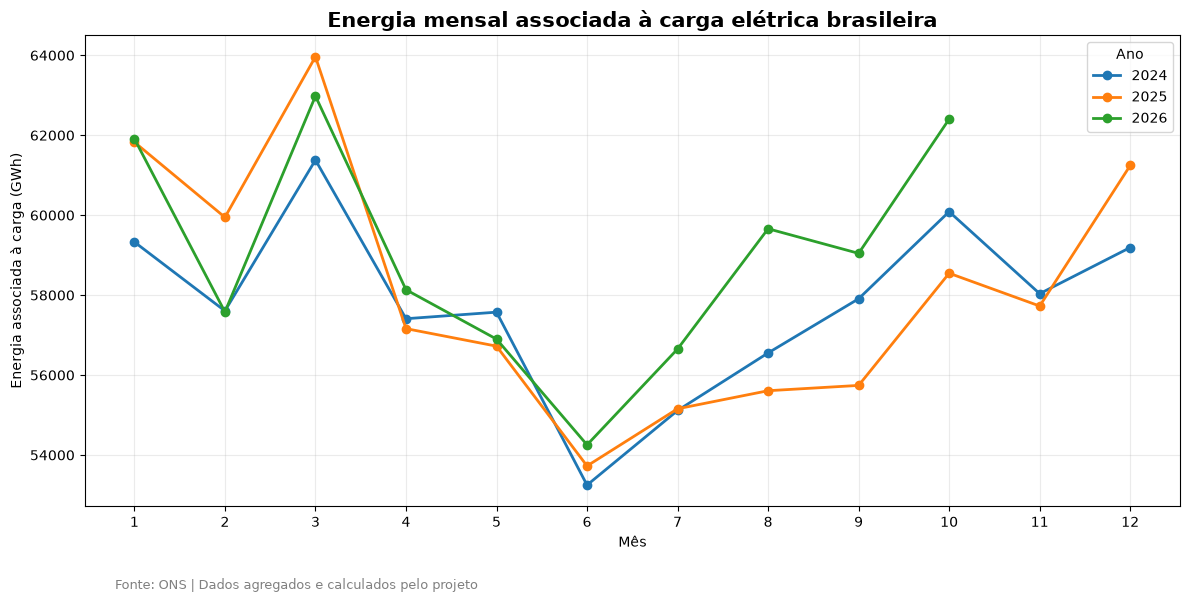

In [6]:

import matplotlib.pyplot as plt

# Transformar dados para comparação anual
df_grafico = df_evolucao.pivot(
    index="mes",
    columns="ano",
    values="energia_gwh"
)

fig, ax = plt.subplots(figsize=(12, 6))

for ano in df_grafico.columns:
    ax.plot(
        df_grafico.index,
        df_grafico[ano],
        marker="o",
        linewidth=2,
        label=str(ano)
    )

ax.set_title(
    "Energia mensal associada à carga elétrica brasileira",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Mês")
ax.set_ylabel("Energia associada à carga (GWh)")
ax.set_xticks(range(1, 13))
ax.legend(title="Ano")
ax.grid(alpha=0.25)

fig.text(0.10, 0.01, "Fonte: ONS | Dados agregados e calculados pelo projeto", fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.05, 1, 1])

# Salvar gráfico para o artigo
pasta_imagens = BASE_DIR / "images"
pasta_imagens.mkdir(exist_ok=True)

plt.savefig(
    pasta_imagens / "01_evolucao_carga.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 7. Crescimento Interanual da Energia

A comparação usa energia mensal em GWh e não ajusta a duração de fevereiro em anos bissextos.


In [7]:

import duckdb
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

arquivo_sql = (
    BASE_DIR / "sql" /
    "02_crescimento_interanual.sql"
)

consulta = arquivo_sql.read_text(encoding="utf-8")

caminho_gold = (
    BASE_DIR / "data" / "gold" /
    "carga_mensal.parquet"
)

consulta = consulta.replace(
    "data/gold/carga_mensal.parquet",
    caminho_gold.as_posix()
)

with duckdb.connect() as con:
    df_yoy = con.execute(consulta).df()

display(df_yoy[df_yoy["ano"] >= 2025].head(12))


,ano,mes,energia_gwh,energia_ano_anterior_gwh,variacao_yoy
12,2025,1,61827.09,59329.14,4.21
13,2025,2,59946.96,57605.51,4.06
14,2025,3,63963.61,61379.71,4.21
15,2025,4,57161.99,57409.79,-0.43
16,2025,5,56723.47,57573.73,-1.48
17,2025,6,53726.54,53247.86,0.90
18,2025,7,55156.70,55113.70,0.08
19,2025,8,55608.46,56553.74,-1.67
20,2025,9,55741.27,57908.88,-3.74
21,2025,10,58547.59,60088.14,-2.56


## 8. Visualização 02 - Variação Interanual
Evolução percentual da demanda elétrica em 2025 e 2026.

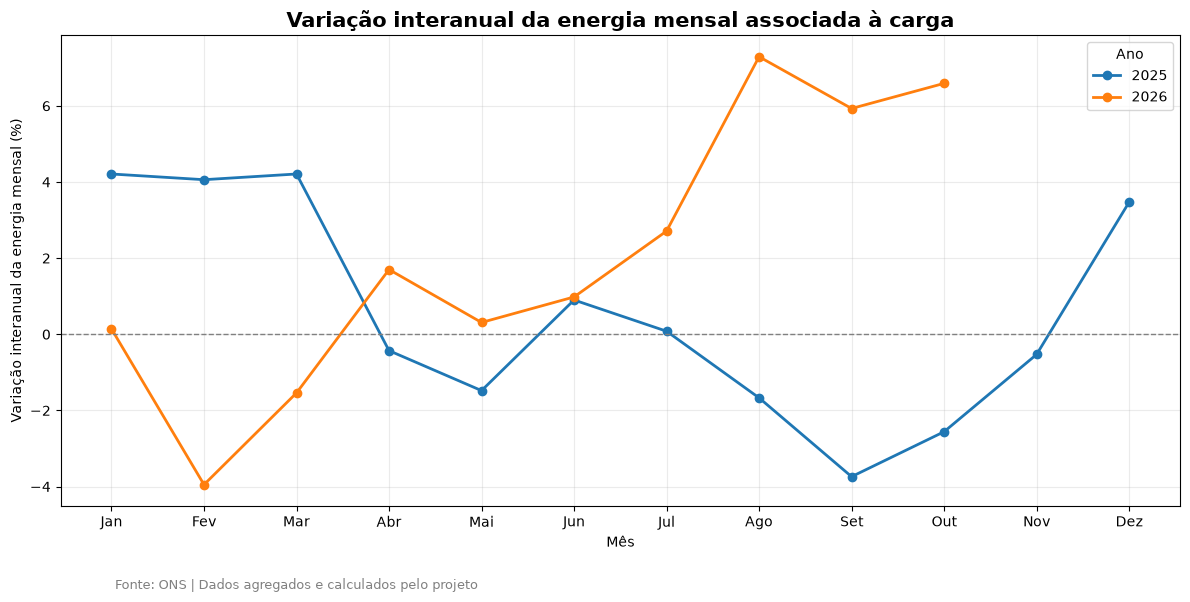

In [8]:

import matplotlib.pyplot as plt

df_plot = df_yoy.dropna(
    subset=["variacao_yoy"]
).copy()

fig, ax = plt.subplots(figsize=(12, 6))

for ano, grupo in df_plot.groupby("ano"):
    ax.plot(
        grupo["mes"],
        grupo["variacao_yoy"],
        marker="o",
        linewidth=2,
        label=str(ano)
    )

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Variação interanual da energia mensal associada à carga",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Mês")
ax.set_ylabel("Variação interanual da energia mensal (%)")

ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Jan", "Fev", "Mar", "Abr",
    "Mai", "Jun", "Jul", "Ago",
    "Set", "Out", "Nov", "Dez"
])

ax.legend(title="Ano")
ax.grid(alpha=0.25)

fig.text(0.10, 0.01, "Fonte: ONS | Dados agregados e calculados pelo projeto", fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.05, 1, 1])

pasta_imagens = BASE_DIR / "images"
pasta_imagens.mkdir(exist_ok=True)

plt.savefig(
    pasta_imagens / "02_variacao_interanual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 9. Comparação Acumulada - Janeiro a Outubro
Análise do crescimento da demanda em períodos equivalentes.

In [9]:

# Comparar janeiro a outubro de cada ano
df_acumulado = (
    df_evolucao[
        df_evolucao["mes"] <= 10
    ]
    .groupby("ano", as_index=False)
    .agg(
        energia_gwh=("energia_gwh", "sum"),
        meses=("mes", "nunique")
    )
)

# Garantir 10 meses completos por ano
df_acumulado = df_acumulado[
    df_acumulado["meses"] == 10
].copy()

df_acumulado["variacao_yoy"] = (
    df_acumulado["energia_gwh"]
    .pct_change() * 100
)

display(df_acumulado)


,ano,energia_gwh,meses,variacao_yoy
0,2024,576210.20,10,NaN
1,2025,578403.68,10,0.380674
2,2026,589520.28,10,1.921945


## 10. Comparação Ajustada por Duração
Análise da carga média diária, eliminando o efeito da diferença de dias entre os anos.

In [10]:
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

from pathlib import Path

# Comparação de carga média em períodos equivalentes
df_ajustado = (
    df_evolucao[df_evolucao["mes"] <= 10]
    .copy()
)

# Obter o número de dias de cada mês
df_ajustado["dias"] = pd.to_datetime(
    dict(
        year=df_ajustado["ano"],
        month=df_ajustado["mes"],
        day=1
    )
).dt.days_in_month

# Energia total do período convertida para carga média
resumo_ajustado = (
    df_ajustado.groupby("ano")
    .apply(
        lambda grupo: pd.Series({
            "energia_gwh": grupo["energia_gwh"].sum(),
            "dias": grupo["dias"].sum()
        }),
        include_groups=False
    )
    .reset_index()
)

resumo_ajustado["carga_media_mwmed"] = (
    resumo_ajustado["energia_gwh"] * 1000
    / (resumo_ajustado["dias"] * 24)
)

resumo_ajustado["variacao_yoy"] = (
    resumo_ajustado["carga_media_mwmed"]
    .pct_change() * 100
)

display(resumo_ajustado)

,ano,energia_gwh,dias,carga_media_mwmed,variacao_yoy
0,2024,576210.20,305.0,78717.240437,NaN
1,2025,578403.68,304.0,79276.820175,0.710873
2,2026,589520.28,304.0,80800.476974,1.921945


## 11. Análise Regional da Carga Elétrica
Comparação da demanda entre os subsistemas do SIN em 2025 e 2026.

In [11]:

import duckdb
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

arquivo_sql = BASE_DIR / "sql" / "03_analise_regional.sql"

consulta = arquivo_sql.read_text(encoding="utf-8")

consulta = consulta.replace(
    "data/gold/carga_mensal.parquet",
    (
        BASE_DIR / "data" / "gold" /
        "carga_mensal.parquet"
    ).as_posix()
)

with duckdb.connect() as con:
    df_regional = con.execute(consulta).df()

display(df_regional)


,id_subsistema,nom_subsistema,carga_media_2025,carga_media_2026,variacao_yoy,diferenca_mwmed
0,N,Norte,8233.67,8763.32,6.43,529.65
1,NE,Nordeste,13181.75,13666.16,3.67,484.42
2,S,Sul,13752.95,14080.36,2.38,327.40
3,SE,Sudeste/Centro-Oeste,44108.45,44290.64,0.41,182.19


## 12. Visualização 03 - Crescimento Regional
Variação percentual da carga média por subsistema.

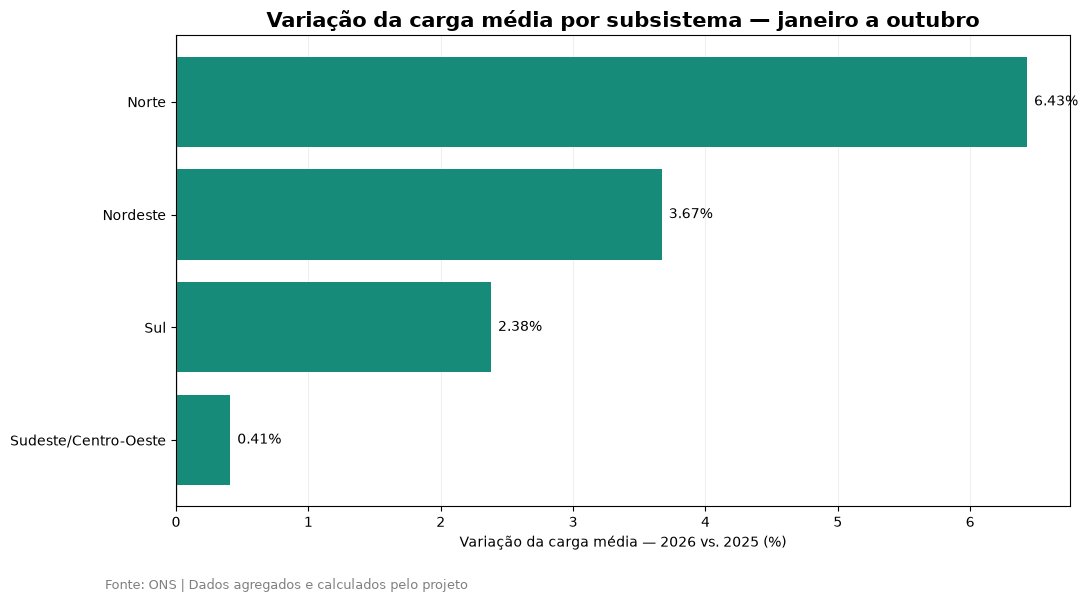

In [12]:

import matplotlib.pyplot as plt

df_plot = df_regional.sort_values(
    "variacao_yoy"
)

fig, ax = plt.subplots(figsize=(11, 6))

cores = [
    "#168B79" if valor >= 0 else "#D65B5B"
    for valor in df_plot["variacao_yoy"]
]

barras = ax.barh(
    df_plot["nom_subsistema"],
    df_plot["variacao_yoy"],
    color=cores
)

ax.axvline(0, color="gray", linewidth=1)

ax.bar_label(
    barras,
    fmt="%.2f%%",
    padding=5
)

ax.set_title(
    "Variação da carga média por subsistema — janeiro a outubro",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Variação da carga média — 2026 vs. 2025 (%)"
)

ax.set_ylabel("")

ax.grid(
    axis="x",
    alpha=0.2
)

ax.set_axisbelow(True)

fig.text(0.10, 0.01, "Fonte: ONS | Dados agregados e calculados pelo projeto", fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.05, 1, 1])

pasta_imagens = BASE_DIR / "images"
pasta_imagens.mkdir(exist_ok=True)

plt.savefig(
    pasta_imagens / "03_crescimento_regional.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 13. Visualização 04 - Contribuição Regional
Diferença absoluta da carga média entre 2025 e 2026.

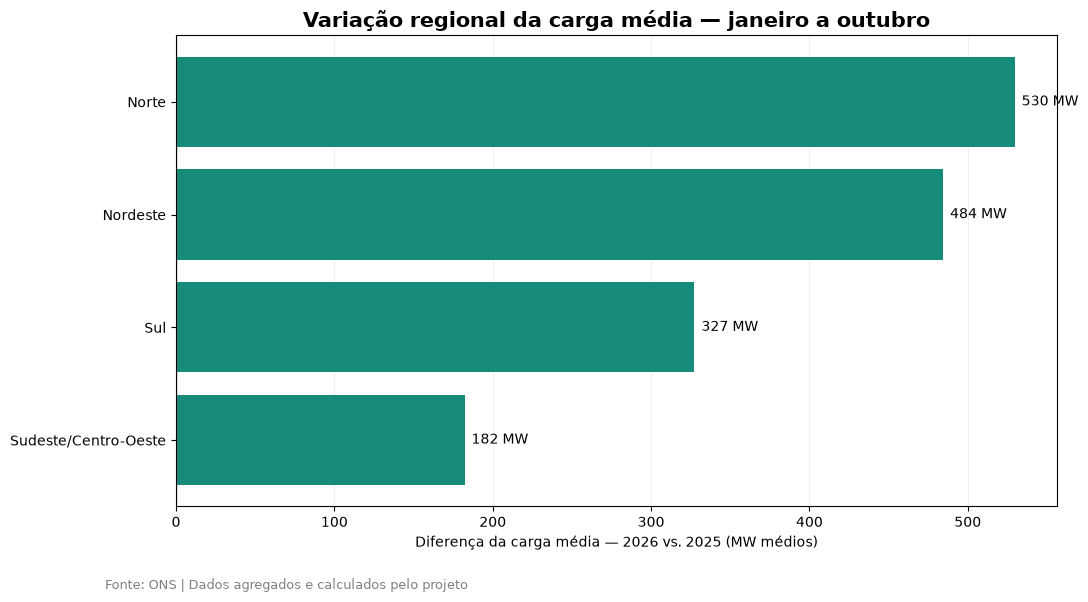

In [13]:

df_plot = df_regional.sort_values(
    "diferenca_mwmed"
)

fig, ax = plt.subplots(figsize=(11, 6))

cores = [
    "#168B79" if valor >= 0 else "#D65B5B"
    for valor in df_plot["diferenca_mwmed"]
]

barras = ax.barh(
    df_plot["nom_subsistema"],
    df_plot["diferenca_mwmed"],
    color=cores
)

ax.axvline(
    0,
    color="gray",
    linewidth=1
)

ax.bar_label(
    barras,
    fmt="%.0f MW",
    padding=5
)

ax.set_title(
    "Variação regional da carga média — janeiro a outubro",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Diferença da carga média — 2026 vs. 2025 (MW médios)"
)

ax.set_ylabel("")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(0.10, 0.01, "Fonte: ONS | Dados agregados e calculados pelo projeto", fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    BASE_DIR / "images" / "04_contribuicao_regional.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
